# 08 · Canonical records, labels and the leakage-controlled co-citation graph (Phase 5)

Input: the citer pool and corpus from notebook 07. Design: `research/audit/PHASE5_DESIGN.md`.

1. **Canonical records.** Duplicate OpenAlex records (same DOI, or same title within a year) are merged in the corpus and in the labels, so a method is never scored down for retrieving a positive's other record.
2. **Labels.** Phase 5 positives are the v2 positives, mapped to canonical ids. Positives that are gone from OpenAlex or lack an abstract are dropped. So is the dev copy `W3012006042` of a test query.
3. **Query duplicates (rule R3).** Pool works that duplicate a query record by DOI, exact title (any year, so earlier versions of living reviews count) or near-title with a shared author, plus a short manual list of the same work under a different title (fixed at Checkpoint A, before any method ran).
4. **Duplicate citers.** Pool records of the same work are merged into one row, so no co-citation edge is counted twice.
5. **Graph.** A citer × document matrix over the corpus. Each row keeps its kind (pool, query record, query duplicate) and a **conservative date**: a YYYY-01-01 date counts as YYYY-12-31, and a citer is never earlier than the latest work it cites (rule R4). Rules R1–R5 are row masks applied per query (`src/cograph.py`).
6. **Reachability under each rule**, plus a sensitivity check on the date rule and a list of the citers that overlap most with a query's positives. The share of positives that some allowed citer cites, with each rule switched off in turn. This bounds what graph expansion can recover, before any method runs.
7. **Unit tests** for every rule (`tests/test_cograph.py`).

In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")

RESEARCH = Path.cwd().parent if Path.cwd().name == "v2" else Path.cwd()
sys.path.insert(0, str(RESEARCH))

import numpy as np
import pandas as pd
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

from src.figures import save, setup_style
setup_style()

In [2]:
DROP_QUERIES = {"https://openalex.org/W3012006042": "dev copy of test query W4247191450 (decision 6)"}
MIN_POSITIVES = 3  # same rule as v2
# Same work under a different title, found at Checkpoint A by listing citers that cite at least half of a
# query's positives; title rules cannot catch these without also matching unrelated papers (e.g. "Mip-NeRF").
MANUAL_QUERY_DUPLICATES = {
    "https://openalex.org/W3011537551": ("https://openalex.org/W4200150166", "NeRF, ECCV 2020 preprint of the CACM paper"),
    "https://openalex.org/W3109585842": ("https://openalex.org/W4200150166", "NeRF, ECCV 2020 conference paper"),
    "https://openalex.org/W2985958369": ("https://openalex.org/W3005073185", "preprint of the query, full title"),
}

In [3]:
import glob
import json

from src.corpus import CITERS, WORKS, citer_pool
from src.eval_v2 import eligible
from src.openalex import normalize_work
from src.pipeline_v2 import load_eval_sets, load_v1_queries

manifest = json.loads((RESEARCH / "v2" / "corpus" / "corpus_manifest.json").read_text())
works = {}
with WORKS.open() as f:
    for line in f:
        w = json.loads(line)
        works[w["id"]] = w
ds = load_eval_sets("random")
sets, splits = ds["sets"], ds["splits"]
query_ids = {q["id"] for q in load_v1_queries()}
pool = citer_pool([json.loads(Path(p).read_text()) for p in sorted(glob.glob(str(CITERS / "*.json")))])
print(f"corpus ids {len(manifest['corpus_ids'])}, cached works {len(works)}, citer pool {len(pool)}, "
      f"query records with a cached work {len(query_ids & set(works))}/{len(query_ids)}")

corpus ids 12096, cached works 16888, citer pool 13572, query records with a cached work 174/174


### 1 · Canonical records

In [4]:
from collections import defaultdict

from src.cograph import canonical_map

v2_positives = {p for s in sets for p in s["positives"]}
records = {}
for pid in manifest["corpus_ids"]:
    rec = normalize_work(works[pid])
    records[pid] = {**rec, "doi": works[pid].get("doi")}
canon = canonical_map(records, prefer=v2_positives)

groups = defaultdict(list)
for pid, c in canon.items():
    groups[c].append(pid)
dup_groups = {c: sorted(m) for c, m in groups.items() if len(m) > 1}
print(f"{len(records)} records -> {len(groups)} canonical works; {len(dup_groups)} duplicate groups "
      f"({sum(len(m) for m in dup_groups.values()) - len(dup_groups)} records merged)")
print(f"groups with two or more v2 positives: {sum(len(set(m) & v2_positives) > 1 for m in dup_groups.values())}; "
      f"groups joining a positive and a non-positive: {sum(0 < len(set(m) & v2_positives) < len(m) for m in dup_groups.values())}")
for c, m in list(dup_groups.items())[:8]:
    print("  ", [x.rsplit('/', 1)[1] for x in m], "|", records[c]["publication_date"][:4], records[c]["title"][:70])

12096 records -> 11968 canonical works; 119 duplicate groups (128 records merged)
groups with two or more v2 positives: 10; groups joining a positive and a non-positive: 12
   ['W1515587369', 'W4299588845'] | 2017 The Discovery of Grounded Theory
   ['W1517222036', 'W24060287'] | 2003 Stability of SARS Coronavirus in Human Specimens and Environment and I
   ['W1534533078', 'W4254896200'] | 2011 Physical interventions to interrupt or reduce the spread of respirator
   ['W1545460766', 'W2000380427'] | 2014 A primer on partial least squares structural equation modeling (PLS-SE
   ['W1554663460', 'W4388297464'] | 1994 Neural networks for pattern recognition
   ['W1605824561', 'W2608014122'] | 2006 Constructing grounded theory : a practical guide through qualitative a
   ['W1606697907', 'W2022101730'] | 1992 Infectious Diseases of Humans: Dynamics and Control
   ['W1651586605', 'W4296886862'] | 2007 Applications of machine learning in cancer prediction and prognosis.


In [5]:
doc_ids = sorted({c for c in canon.values() if eligible(records[c])})
print(f"candidate corpus after canonicalization and eligibility: {len(doc_ids)} works")

candidate corpus after canonicalization and eligibility: 11967 works


### 2 · Labels

In [6]:
doc_set = set(doc_ids)
labels, dropped, lost = {}, [], []
for s in sets:
    qid = s["pi_id"]
    if qid in DROP_QUERIES:
        dropped.append({"pi_id": qid, "reason": DROP_QUERIES[qid]})
        continue
    pos = []
    for p in s["positives"]:
        c = canon.get(p)
        if c is None or c not in doc_set:
            lost.append({"pi_id": qid, "positive": p, "split": splits[qid],
                         "reason": "not in OpenAlex" if p not in works else "no abstract"})
        elif c not in pos:
            pos.append(c)
    if len(pos) < MIN_POSITIVES:
        dropped.append({"pi_id": qid, "reason": f"{len(pos)} positives left"})
        continue
    labels[qid] = {"split": splits[qid], "date": s["pi_date"], "title": s["pi_title"], "positives": sorted(pos)}

lab = pd.DataFrame([{"split": v["split"], "n_pos": len(v["positives"])} for v in labels.values()])
print(lab.groupby("split").n_pos.agg(["size", "sum", "median", "min", "max"]))
print(f"v2 positive slots {sum(len(s['positives']) for s in sets)} -> Phase 5 {lab.n_pos.sum()}; "
      f"positives dropped: {len(lost)}; merged as duplicates: "
      f"{sum(len(s['positives']) for s in sets if s['pi_id'] in labels) - lab.n_pos.sum() - sum(l['pi_id'] in labels for l in lost)}")
print(pd.DataFrame(lost).to_string(index=False))
print(pd.DataFrame(dropped).to_string(index=False))

       size  sum  median  min  max
split                             
dev      48  364     7.0    3   13
test    118  855     7.0    3   13
v2 positive slots 1247 -> Phase 5 1219; positives dropped: 5; merged as duplicates: 9
                           pi_id                         positive split          reason
https://openalex.org/W3005073185 https://openalex.org/W2951482518  test not in OpenAlex
https://openalex.org/W3173556047 https://openalex.org/W3168183489  test not in OpenAlex
https://openalex.org/W4388291555 https://openalex.org/W3012048021   dev     no abstract
https://openalex.org/W4389523957 https://openalex.org/W3090325631  test not in OpenAlex
https://openalex.org/W4389523957 https://openalex.org/W4226369848  test not in OpenAlex
                           pi_id                                          reason
https://openalex.org/W3012006042 dev copy of test query W4247191450 (decision 6)
https://openalex.org/W4388291555                                2 positives left


### 3 · Query duplicates in the citer pool (R3)

Every match is listed so the rule can be checked by eye.

In [7]:
from src.cograph import author_ids, query_duplicates

queries = {q: works[q] for q in query_ids}
qdups = query_duplicates(pool, queries)
for cid, (qid, why) in MANUAL_QUERY_DUPLICATES.items():
    assert cid in pool and cid not in qdups, cid
    qdups[cid] = (qid, "manual")
rows = []
for cid, (qid, reason) in sorted(qdups.items(), key=lambda x: (x[1][1], x[1][0])):
    c, q = pool[cid], queries[qid]
    rows.append({"reason": reason, "citer": cid.rsplit("/", 1)[1], "citer_date": c["publication_date"],
                 "query": qid.rsplit("/", 1)[1], "query_date": q["publication_date"],
                 "shared_authors": len(author_ids(c) & author_ids(q)),
                 "shared_refs": f"{len(set(c['referenced_works']) & set(q['referenced_works']))}/{len(q['referenced_works'])}",
                 "title": c["title"][:60]})
qd = pd.DataFrame(rows)
print(qd.reason.value_counts().to_dict(), "| query records in the pool:", len(set(pool) & query_ids))
qd

{'title': 12, 'near-title': 7, 'manual': 3, 'doi': 1} | query records in the pool: 3


,reason,citer,citer_date,query,query_date,shared_authors,shared_refs,title
0,doi,W4229036110,2021-05-07,W3159396736,2022-01-12,1,9/11,Congenital Adrenal Hyperplasia—Current Insight...
1,manual,W2985958369,2019-11-15,W3005073185,2020-02-05,2,10/13,"""How do I fool you?"": Manipulating User Trust ..."
2,manual,W3011537551,2020-03-19,W4200150166,2021-12-17,6,12/17,NeRF: Representing Scenes as Neural Radiance F...
3,manual,W3109585842,2020-01-01,W4200150166,2021-12-17,6,16/17,NeRF: Representing Scenes as Neural Radiance F...
4,near-title,W2921679472,2019-03-15,W3178636644,2021-06-01,3,2/13,A technical comparison of three low earth orbi...
5,near-title,W2984194970,2019-11-11,W3199710005,2021-09-16,13,7/14,THE CONCISE GUIDE TO PHARMACOLOGY 2019/20: G p...
6,near-title,W2765684626,2017-10-21,W3199710005,2021-09-16,10,7/14,THE CONCISE GUIDE TO PHARMACOLOGY 2017/18: G p...
7,near-title,W4206138109,2020-06-18,W4205754343,2021-09-08,9,4/10,International Committee for Monitoring Assiste...
8,near-title,W4236533978,2014-05-02,W4205754343,2021-09-08,5,0/10,International Committee for Monitoring Assiste...
9,near-title,W4231523544,2014-12-13,W4205754343,2021-09-08,6,2/10,International Committee for Monitoring Assiste...


### 3b · Duplicate citers

Records of the same work in the pool (same DOI, or same title within a year) become one row with the union of their references and the latest member date.

In [8]:
from src.cograph import merge_duplicate_citers

pool_recs = {c: {"title": w.get("title"), "doi": w.get("doi"), "publication_date": w.get("publication_date"), "abstract": ""}
             for c, w in pool.items() if c not in query_ids}
citer_canon = canonical_map(pool_recs)
merged_pool = merge_duplicate_citers({c: pool[c] for c in pool_recs}, citer_canon)
merged_groups = {c: m["members"] for c, m in merged_pool.items() if len(m["members"]) > 1}
dup_citers = {citer_canon[c] for c in qdups}  # a merged row is a query duplicate if any member is
print(f"{len(pool_recs)} pool records (query records excluded) -> {len(merged_pool)} citer rows; "
      f"{len(merged_groups)} groups merged {sum(len(m) for m in merged_groups.values()) - len(merged_groups)} records")
print(f"query-duplicate rows after merging: {len(dup_citers)}")

13569 pool records (query records excluded) -> 13461 citer rows; 89 groups merged 108 records
query-duplicate rows after merging: 16


### 4 · Graph

In [9]:
from src.cograph import build_graph

citers = {**merged_pool, **{q: works[q] for q in query_ids}}  # query records are rows too, so R1/R2/R5 are testable
ref_dates = {k: w.get("publication_date") for k, w in works.items() if w.get("publication_date")}
ref_dates.update({k: w.get("publication_date") for k, w in pool.items() if w.get("publication_date")})
g = build_graph(citers, doc_ids, canon, query_ids, dup_citers, ref_dates=ref_dates)
g_recorded = build_graph(citers, doc_ids, canon, query_ids, dup_citers)  # dates as recorded, for the sensitivity check
nnz_rows = np.asarray(g.C.sum(1)).ravel()
pool_rows = ~g.is_query & ~g.is_query_dup
moved = g.citer_day != g_recorded.citer_day
print(f"{g.C.shape[0]} citer rows ({g.is_query.sum()} query records, {g.is_query_dup.sum()} query duplicates), "
      f"{g.C.shape[1]} docs, {g.C.nnz} citation edges")
print(f"corpus references per pool citer: median {np.median(nnz_rows[pool_rows]):.0f}, "
      f"mean {nnz_rows[pool_rows].mean():.1f}; pool citers citing no corpus work: {(nnz_rows[pool_rows] == 0).sum()}")
jan1 = np.array([(citers[c].get("publication_date") or "").endswith("-01-01") for c in g.citer_ids])
print(f"pool rows dated YYYY-01-01: {(jan1 & pool_rows).sum()} of {pool_rows.sum()}; "
      f"pool rows whose conservative date is later than recorded: {(moved & pool_rows).sum()}")

13635 citer rows (174 query records, 16 query duplicates), 11967 docs, 126377 citation edges
corpus references per pool citer: median 5, mean 9.3; pool citers citing no corpus work: 1996
pool rows dated YYYY-01-01: 3193 of 13445; pool rows whose conservative date is later than recorded: 5097


### 5 · Reachability of positives under each rule

A positive is *reachable* for its query if at least one allowed citer cites it. Graph expansion cannot recover an unreachable positive. Each row switches one rule off. The canary adds the query's own reference list, so every positive must become reachable.

In [10]:
from dataclasses import replace

from src.cograph import Rules, effective_day

def with_days(days):
    return replace(g, citer_day=np.asarray(days, dtype=np.int64))

CONDITIONS = {
    "all rules (normal)": (g, Rules()),
    "R3 off: keep query duplicates": (g, Rules(drop_query_dups=False)),
    "R4 off: allow later citers": (g, Rules(temporal=False)),
    "R5 off: allow other query records": (g, Rules(drop_query_records=False)),
    "R3–R5 off": (g, Rules(temporal=False, drop_query_dups=False, drop_query_records=False)),
    "canary: add the query's own references": (g, Rules(canary=True)),
    # sensitivity of R4 to the date rule
    "R4 dates as recorded": (g_recorded, Rules()),
    "R4 YYYY-01-01 rule only": (with_days([effective_day(citers[c]) for c in g.citer_ids]), Rules()),
    "R4 reference-date rule only": (with_days([effective_day(citers[c], ref_dates, year_only_jan1=False) for c in g.citer_ids]), Rules()),
    "R4 plus a 365-day margin": (with_days(g.citer_day + 365), Rules()),
}
idx = g.doc_index
reach = []
for qid, lab_q in labels.items():
    cols = [idx[p] for p in lab_q["positives"]]
    for name, (graph, rules) in CONDITIONS.items():
        mask = graph.allowed(qid, lab_q["date"], rules)
        deg = np.asarray(graph.C[mask][:, cols].sum(0)).ravel()
        reach.append({"pi_id": qid, "split": lab_q["split"], "condition": name,
                      "n_pos": len(cols), "reachable": int((deg > 0).sum())})
reach = pd.DataFrame(reach)
reach_tab = (reach.groupby(["condition", "split"])[["n_pos", "reachable"]].sum()
             .assign(share=lambda d: (d.reachable / d.n_pos).round(3)).unstack("split"))
reach_tab.loc[list(CONDITIONS)]

n_pos      reachable       share       
split                                    dev test       dev test    dev   test
condition                                                                     
all rules (normal)                       364  855       193  468  0.530  0.547
R3 off: keep query duplicates            364  855       197  484  0.541  0.566
R4 off: allow later citers               364  855       244  582  0.670  0.681
R5 off: allow other query records        364  855       198  471  0.544  0.551
R3–R5 off                                364  855       248  599  0.681  0.701
canary: add the query's own references   364  855       364  855  1.000  1.000
R4 dates as recorded                     364  855       227  538  0.624  0.629
R4 YYYY-01-01 rule only                  364  855       213  506  0.585  0.592
R4 reference-date rule only              364  855       204  489  0.560  0.572
R4 plus a 365-day margin                 364  855       112  229  0.308  0.268

In [11]:
assert (reach[reach.condition.str.startswith("canary")].pipe(lambda d: d.reachable == d.n_pos)).all(), \
    "canary must make every positive reachable"
print("canary check passed: every positive is reachable when the query's own references are added")

canary check passed: every positive is reachable when the query's own references are added


### 5b · Citers that overlap most with a query's positives

Under all rules, every allowed citer that cites at least half of a query's positives. A citer citing many positives is the legitimate mechanism of co-citation expansion (reviews, earlier work by the same group). The list is shown so that remaining duplicates or misdated records can be spotted by eye.

In [12]:
rows = []
for qid, lab_q in labels.items():
    cols = [idx[p] for p in lab_q["positives"]]
    mask = g.allowed(qid, lab_q["date"], Rules())
    share = np.asarray(g.C[:, cols].sum(1)).ravel() / len(cols)
    for r in np.flatnonzero(mask & (share >= 0.5)):
        c = citers[g.citer_ids[r]]
        rows.append({"split": lab_q["split"], "overlap": round(float(share[r]), 2), "query": qid.rsplit("/", 1)[1],
                     "query_date": lab_q["date"], "citer": g.citer_ids[r].rsplit("/", 1)[1],
                     "citer_date": c.get("publication_date"), "type": c.get("type"),
                     "shared_authors": len(author_ids(c) & author_ids(works[qid])), "title": (c.get("title") or "")[:60]})
overlap = pd.DataFrame(rows).sort_values(["overlap", "query"], ascending=[False, True])
print(overlap.groupby("split").size().to_dict(), "| with a shared author:", int((overlap.shared_authors > 0).sum()))
overlap.head(40)

{'dev': 30, 'test': 66} | with a shared author: 17


,split,overlap,query,query_date,citer,citer_date,type,shared_authors,title
33,test,0.80,W3152052045,2021-04-07,W2774402874,2017-12-06,article,0,The position of reporting guidelines in qualit...
35,test,0.80,W3152052045,2021-04-07,W3096740851,2020-10-27,editorial,0,On the Use and Value of Reporting Guidelines i...
65,test,0.75,W4220920296,2022-03-23,W4220796142,2022-03-07,preprint,0,Satellite quantification of oil and natural ga...
10,test,0.71,W3027407129,2020-05-22,W2900114513,2018-11-08,article,0,Evolving changes in M-protein and hemoglobin a...
12,test,0.71,W3027407129,2020-05-22,W3024557577,2020-05-13,article,0,Treatment of Smoldering Multiple Myeloma: Read...
48,dev,0.71,W4200150166,2021-12-17,W3092948912,2020-10-15,preprint,0,NeRF++: Analyzing and Improving Neural Radianc...
0,test,0.67,W2997681568,2020-01-06,W2595557058,2017-03-15,article,0,The need to approximate the use-case in clinic...
55,test,0.67,W4213177438,2022-02-15,W3213334042,2021-11-06,article,0,"Role of oncogenic KRAS in the prognosis, diagn..."
59,test,0.67,W4213177438,2022-02-15,W4205508655,2022-01-10,article,0,Targeting the undruggable oncogenic KRAS: the ...
64,test,0.67,W4220831878,2022-03-04,W4205133150,2022-01-20,preprint,2,On Strictly Enforced Mass Conservation Constra...


### 6 · Membership asymmetry

Non-positives entered the corpus because at least 5 pool citers cite them, while positives were added whatever their degree (decision 3). Degree alone therefore separates the two groups to some extent. Notebook 09 measures this with a degree-only ranker; here we only describe it, using all pool citers (no date filter).

In [13]:
pos_all = {p for v in labels.values() for p in v["positives"]}
deg = g.degree(pool_rows)
is_pos = np.array([d in pos_all for d in doc_ids])
deg_tab = pd.DataFrame({"group": np.where(is_pos, "positives", "non-positives"), "degree": deg})
print(deg_tab.groupby("group").degree.describe(percentiles=[.1, .25, .5, .75, .9]).round(1))
print(f"positives with degree 0: {(deg[is_pos] == 0).mean():.1%}; non-positives with degree < 5 after removing "
      f"query records and duplicates: {(deg[~is_pos] < 5).sum()}")

                 count  mean   std  min  10%  25%  50%   75%   90%    max
group                                                                    
non-positives  10805.0  10.3  12.7  0.0  5.0  5.0  7.0  11.0  18.0  458.0
positives       1162.0  11.4  35.3  0.0  0.0  0.0  2.0   8.0  24.0  504.0
positives with degree 0: 33.6%; non-positives with degree < 5 after removing query records and duplicates: 260


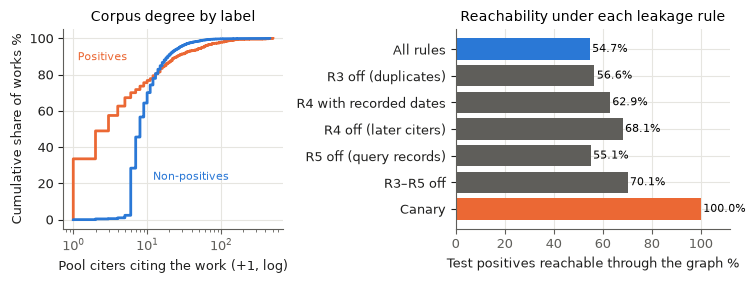

In [14]:
import matplotlib.pyplot as plt

from src.figures import INK_2, SLOTS

fig, axes = plt.subplots(1, 2, figsize=(7.6, 2.9), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
for name, sel, color, xy in (("Positives", is_pos, SLOTS[1], (1.15, 88)), ("Non-positives", ~is_pos, SLOTS[0], (12, 22))):
    x = np.sort(deg[sel] + 1)
    y = np.arange(1, len(x) + 1) / len(x)
    ax.step(x, y * 100, where="post", color=color)
    ax.text(*xy, name, color=color, fontsize=8)
ax.set_xscale("log")
ax.set_xlabel("Pool citers citing the work (+1, log)")
ax.set_ylabel("Cumulative share of works %")
ax.set_title("Corpus degree by label")

ax = axes[1]
shown = {"all rules (normal)": "All rules", "R3 off: keep query duplicates": "R3 off (duplicates)",
         "R4 dates as recorded": "R4 with recorded dates", "R4 off: allow later citers": "R4 off (later citers)",
         "R5 off: allow other query records": "R5 off (query records)", "R3–R5 off": "R3–R5 off",
         "canary: add the query's own references": "Canary"}
test = reach_tab.xs("test", axis=1, level="split")["share"].loc[list(shown)] * 100
names = list(shown.values())
colors = [SLOTS[0]] + [INK_2] * 5 + [SLOTS[1]]
ax.barh(range(len(test)), test.values, color=colors)
for i, v in enumerate(test.values):
    ax.text(v + 1, i, f"{v:.1f}%", va="center", fontsize=8)
ax.set_yticks(range(len(test)), names)
ax.invert_yaxis()
ax.set_xlim(0, 112)
ax.set_xlabel("Test positives reachable through the graph %")
ax.set_title("Reachability under each leakage rule")
fig.tight_layout()
save(fig, "08_graph_degree_reachability")
plt.show()

### 7 · Unit tests for the leakage rules

In [15]:
import subprocess

res = subprocess.run([sys.executable, "-m", "pytest", "tests", "-q", "--color=no", "-p", "no:cacheprovider"], cwd=RESEARCH, capture_output=True, text=True)
print(res.stdout[-1500:])
assert res.returncode == 0, "unit tests failed"

..............                                                           [100%]
14 passed in 0.17s



### Save

In [16]:
import scipy.sparse as sp

out_dir = RESEARCH / "data" / "v2" / "corpus" / "graph"
out_dir.mkdir(parents=True, exist_ok=True)
sp.save_npz(out_dir / "C.npz", g.C)
(out_dir / "meta.json").write_text(json.dumps({
    "doc_ids": g.doc_ids, "citer_ids": g.citer_ids, "citer_day": g.citer_day.tolist(),
    "is_query": g.is_query.tolist(), "is_query_dup": g.is_query_dup.tolist()}))
corpus_dir = RESEARCH / "v2" / "corpus"
(corpus_dir / "labels.json").write_text(json.dumps(labels, indent=1, ensure_ascii=False))
(corpus_dir / "canonical_groups.json").write_text(json.dumps(dup_groups, indent=1))
(corpus_dir / "query_duplicates.json").write_text(json.dumps({c: list(v) for c, v in sorted(qdups.items())}, indent=1))
(corpus_dir / "citer_groups.json").write_text(json.dumps(merged_groups, indent=1))
print("saved graph to", out_dir.relative_to(RESEARCH), "and labels/groups/duplicates to", corpus_dir.relative_to(RESEARCH))

saved graph to data/v2/corpus/graph and labels/groups/duplicates to v2/corpus


### Findings

- **Canonical records.** The 12,096 corpus records form 11,968 works (119 duplicate groups, 128 records merged). 10 groups join two v2 positives; 12 join a positive with a non-positive, which would otherwise have been a guaranteed false negative. **The candidate corpus holds 11,967 works.**
- **Labels.** 1,247 v2 positive slots become 1,219: 5 positives dropped (4 gone from OpenAlex, 1 without an abstract) and 9 merged as duplicates. Dev loses `W3012006042` (decision 6) and `W4388291555` (2 positives left). **48 dev queries (364 positives), 118 test queries (855 positives).**
- **R3 matters.** 23 pool records duplicate a query record: 12 by exact title, 7 by near-title with shared authors, 1 by DOI, and 3 from the manual list (the NeRF ECCV paper in two records, and the full-title preprint of *"How do I fool you?"*). 3 query records are also in the pool.
  - A 2012 record titled *Electronic cigarettes for smoking cessation.* shares all 10 of the 2020 query's references but no author id.
- **Duplicate citers.** 13,569 pool records merge into 13,461 citer rows (89 groups, 108 records). The 23 query duplicates become 16 rows.
- **Conservative dates (R4).** 3,193 of 13,445 pool rows are dated YYYY-01-01, often a year-only date. The final rule makes 5,097 rows later than recorded: Jan 1 counts as Dec 31, and no citer predates a work it cites.
- **Graph.** 13,635 citer rows (174 query records, 16 query duplicates), 11,967 documents, 126,377 citation edges. Pool citers cite a median of 5 corpus works; 1,996 cite none.
- **Reachability** (test / dev): share of positives that at least one allowed citer cites.
  - **All rules: 54.7% / 53.0%.** This caps what graph expansion can recover; 45% of test positives have no allowed citer.
  - Each relaxation raises it, which is the size of that leak path:

    | Relaxation | Test | Dev |
    |---|---|---|
    | Recorded dates instead of conservative ones | 62.9% | 62.4% |
    | YYYY-01-01 rule only | 59.2% | 58.5% |
    | Reference-date rule only | 57.2% | 56.0% |
    | R3 off | 56.6% | 54.1% |
    | R4 off | 68.1% | 67.0% |
    | R5 off | 55.1% | 54.4% |
    | R3–R5 off | 70.1% | 68.1% |

  - A 365-day margin on top of the conservative dates gives 26.8% / 30.8%; it is a sensitivity check only.
  - **The canary reaches 100%** on both splits, as it must.
- **High-overlap citers.** Under all rules, 66 test and 30 dev citer rows cite at least half of a query's positives, none more than 80%. The top of the list is mostly reviews and commentaries on the query's topic; 17 rows share an author with the query. No exact copy is left in it.
- **Membership asymmetry, by construction (decision 3).** Non-positives have a median of 7 pool citers (260 fall below 5 once duplicates are merged and removed). 33.6% of positives have none (median 2), but they have a heavier tail (90th percentile 24 vs 18). Notebook 09 tests a degree-only ranker.
- **Unit tests.** All 14 pass (`tests/test_cograph.py`), covering R1/R2, R3 (exact and near-title), R4 (strict, Jan 1, reference dates), R5, missing dates, canonical references, canonicalization, citer merging and degree-preserving rewiring.
- **Figure.** `08_graph_degree_reachability`.
